# Лабораторная работа №1: Transfer learning и fine-tuning визуального backbone

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
- Сравнить frozen, partial и full fine-tuning ResNet18.
- Построить confusion matrix и проверить corruption shift.


## Теоретическая часть

Предобученный backbone реализует отображение $f_\theta(x)=z$. Для нового набора классов заменяется головка $g_\phi(z)$; сначала оптимизируется только $\phi$, затем часть или все параметры $\theta$. Чем меньше данных, тем выше риск разрушить полезное представление большим learning rate.

![Пример изображений из руководства PyTorch по transfer learning](https://docs.pytorch.org/tutorials/_images/sphx_glr_transfer_learning_tutorial_001.png)

Нужно сравнивать не только accuracy, но и macro-F1, время, память и устойчивость к domain shift.


### Математическая постановка

Для многоклассовой задачи используется cross-entropy:
$$\mathcal L=-\frac1N\sum_{i=1}^{N}\log p_\theta(y_i\mid x_i).$$
Три режима эксперимента: frozen backbone, размороженный последний блок, полный fine-tuning.


### Материалы

- [PyTorch Transfer Learning Tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [torchvision models](https://pytorch.org/vision/stable/models.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
2. Сравнить frozen, partial и full fine-tuning ResNet18.
3. Построить confusion matrix и проверить corruption shift.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** ResNet18, FP32/FP16, 32–224 px.
- **Ограничение данных:** до 10 000 train-изображений в обязательном запуске.
- **Fallback:** CPU/FAST_DEV_RUN на подвыборке.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Разделение CIFAR-10

*Вес: 1 балл.*

**Постановка.** Изоляция test необходима для оценки обобщения без подбора по тестовым меткам.

Выполните следующие действия:
1. Загрузите CIFAR-10 и разделите train на стратифицированные train и validation.
2. Подготовьте DataLoader с детерминированным test-преобразованием.

**Результат.** Непересекающиеся train, validation и test и загрузчики train_loader, val_loader, test_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 1. Разделение CIFAR-10 ===
import torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset, Dataset
from sklearn.model_selection import train_test_split

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
CFG = {
    "img_size": 32 if FAST_DEV_RUN else 96,       # CIFAR апсемплим до 96 px — ближе к масштабу ImageNet
    "n_train": 512 if FAST_DEV_RUN else 10_000,   # лимит из профиля вычислений
    "n_val": 256 if FAST_DEV_RUN else 5_000,
    "n_test": 256 if FAST_DEV_RUN else 10_000,
    "epochs": 1 if FAST_DEV_RUN else 3,
    "batch_size": 64 if FAST_DEV_RUN else 128,
    "lr_head": 1e-3, "lr_backbone": 1e-4, "weight_decay": 1e-4,
    "num_workers": 0 if FAST_DEV_RUN else 2,
}
(ARTIFACTS / "config.json").write_text(json.dumps(CFG, indent=2))

# Нормализация ImageNet выполняется внутри модели, поэтому датасеты отдают пиксели в [0, 1]:
# это позволяет корректно добавлять шум в пространстве пикселей (этапы 5, 6, 10).
train_tf = T.Compose([T.Resize(CFG["img_size"]), T.RandomCrop(CFG["img_size"], padding=CFG["img_size"] // 8),
                      T.RandomHorizontalFlip(), T.ToTensor()])
eval_tf = T.Compose([T.Resize(CFG["img_size"]), T.ToTensor()])  # детерминированное преобразование

def load_cifar(train, transform):
    """Возвращает (dataset, labels). Синтетика допускается только в FAST_DEV_RUN без доступа к сети."""
    try:
        ds = torchvision.datasets.CIFAR10(DATA_ROOT, train=train, transform=transform, download=True)
        return ds, np.array(ds.targets)
    except Exception as e:
        if not FAST_DEV_RUN:
            raise
        print("CIFAR-10 недоступен, smoke-режим на FakeData:", type(e).__name__)
        ds = torchvision.datasets.FakeData(2000, (3, 32, 32), 10, transform=transform, random_offset=0 if train else 10**6)
        return ds, np.array([ds[i][1] for i in range(len(ds))])

train_full_aug, y_full = load_cifar(True, train_tf)   # тот же train, но с аугментацией
train_full_eval, _ = load_cifar(True, eval_tf)        # для validation — без аугментации
test_full, y_test_full = load_cifar(False, eval_tf)

idx_all = np.arange(len(y_full))
idx_train, idx_rest = train_test_split(idx_all, train_size=CFG["n_train"], stratify=y_full, random_state=SEED)
idx_val, _ = train_test_split(idx_rest, train_size=CFG["n_val"], stratify=y_full[idx_rest], random_state=SEED)
idx_test = np.arange(len(y_test_full))
if CFG["n_test"] < len(idx_test):
    idx_test, _ = train_test_split(idx_test, train_size=CFG["n_test"], stratify=y_test_full, random_state=SEED)
idx_test = np.sort(idx_test)

train_ds = Subset(train_full_aug, idx_train)
val_ds = Subset(train_full_eval, idx_val)
test_ds = Subset(test_full, idx_test)
y_val, y_test = y_full[idx_val], y_test_full[idx_test]

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, CFG["batch_size"], shuffle=True, generator=g, num_workers=CFG["num_workers"])
val_loader = DataLoader(val_ds, 256, shuffle=False, num_workers=CFG["num_workers"])
test_loader = DataLoader(test_ds, 256, shuffle=False, num_workers=CFG["num_workers"])

json.dump({"train": idx_train.tolist(), "val": idx_val.tolist(), "test": idx_test.tolist()}, open(ARTIFACTS / "split.json", "w"))
check(len(set(idx_train) & set(idx_val)) == 0, "train и validation не пересекаются (test — отдельный файл CIFAR)")
check(np.allclose(np.bincount(y_full[idx_train], minlength=10) / len(idx_train),
                  np.bincount(y_full[idx_val], minlength=10) / len(idx_val), atol=0.01), "стратификация сохраняет доли классов")
x0a, x0b = test_ds[0][0], test_ds[0][0]
check(torch.equal(x0a, x0b), "test-преобразование детерминировано")
print({"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)})

100%|██████████| 170M/170M [24:12<00:00, 117kB/s]


✔ train и validation не пересекаются (test — отдельный файл CIFAR)
✔ стратификация сохраняет доли классов
✔ test-преобразование детерминировано
{'train': 10000, 'val': 5000, 'test': 10000}


### Backbone и функции обучения

*Вес: 1 балл.*

**Постановка.** Режимы заморозки изменяют множество обновляемых параметров. Сравнивать их можно лишь при одинаковой функции потерь.

Выполните следующие действия:
1. Создайте ResNet18 с новой десятиклассовой головой.
2. Определите функции обучения и вычисления accuracy, macro-F1, матрицы ошибок.

**Результат.** Функции build_model, train_epoch и evaluate.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 2. Backbone и функции обучения ===
from torchvision.models import resnet18, ResNet18_Weights, efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

def _pretrained(fn, weights):
    try:
        return fn(weights=weights)
    except Exception as e:
        if not FAST_DEV_RUN:
            raise
        print("pretrained-веса недоступны, smoke-режим без них:", type(e).__name__)
        return fn(weights=None)

class Classifier(nn.Module):
    """Нормализация ImageNet + backbone; head/last_block нужны для режимов заморозки."""
    def __init__(self, net, head, last_block):
        super().__init__()
        self.norm = T.Normalize(MEAN, STD)
        self.net, self.head, self.last_block = net, head, last_block
    def forward(self, x):
        return self.net(self.norm(x))

def build_model(arch="resnet18", mode="full", num_classes=10):
    assert mode in ("frozen", "partial", "full")
    if arch == "resnet18":
        net = _pretrained(resnet18, ResNet18_Weights.IMAGENET1K_V1)
        net.fc = nn.Linear(net.fc.in_features, num_classes)
        head, last = net.fc, net.layer4
    elif arch == "efficientnet_b0":
        net = _pretrained(efficientnet_b0, EfficientNet_B0_Weights.IMAGENET1K_V1)
        net.classifier[1] = nn.Linear(net.classifier[1].in_features, num_classes)
        head, last = net.classifier, net.features[-2:]   # последний MBConv-блок + 1x1 conv
    else:
        raise ValueError(arch)
    for p in net.parameters():
        p.requires_grad = (mode == "full")
    if mode in ("frozen", "partial"):
        for p in head.parameters(): p.requires_grad = True
    if mode == "partial":
        for p in last.parameters(): p.requires_grad = True
    return Classifier(net, head, last).to(DEVICE)

def count_params(model):
    return {"trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "total": sum(p.numel() for p in model.parameters())}

def make_optimizer(model):
    head_ids = {id(p) for p in model.head.parameters()}
    head = [p for p in model.parameters() if p.requires_grad and id(p) in head_ids]
    body = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [{"params": head, "lr": CFG["lr_head"]}]
    if body: groups.append({"params": body, "lr": CFG["lr_backbone"]})
    return torch.optim.AdamW(groups, weight_decay=CFG["weight_decay"])

def set_train_mode(model):
    """BatchNorm в полностью замороженных блоках остаётся в eval, чтобы frozen-режим действительно не менял backbone."""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

USE_AMP = DEVICE == "cuda"
criterion = nn.CrossEntropyLoss()   # одинаковая функция потерь для всех режимов

def train_epoch(model, loader, optimizer, scaler=None):
    set_train_mode(model)
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            loss = criterion(model(x), y)
        if scaler is not None:
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        else:
            loss.backward(); optimizer.step()
        total += loss.item() * len(y); n += len(y)
    return total / n

@torch.no_grad()
def predict(model, loader, sigma=0.0, seed=SEED):
    """Предсказания; при sigma>0 к пикселям [0,1] добавляется гауссов шум с фиксированным seed на батч."""
    model.eval()
    preds, labels = [], []
    for b, (x, y) in enumerate(loader):
        if sigma > 0:
            gen = torch.Generator().manual_seed(seed + b)
            x = (x + sigma * torch.randn(x.shape, generator=gen)).clamp(0, 1)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(x.to(DEVICE))
        preds.append(out.argmax(1).cpu()); labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

def evaluate(model, loader, sigma=0.0):
    p, y = predict(model, loader, sigma)
    return {"accuracy": float(accuracy_score(y, p)), "macro_f1": float(f1_score(y, p, average="macro")),
            "confusion_matrix": confusion_matrix(y, p, labels=list(range(10))).tolist(), "preds": p, "labels": y}

def fit(model, name, epochs=None):
    """Обучение с checkpoint после каждой эпохи; при перезапуске продолжает с последней эпохи."""
    epochs = epochs or CFG["epochs"]
    ckpt_path = ARTIFACTS / f"{name}_last.pt"
    opt = make_optimizer(model)
    scaler = torch.amp.GradScaler("cuda") if USE_AMP else None
    state = {"epoch": 0, "history": [], "train_time_s": 0.0}
    if ckpt_path.exists():
        ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); state = ck["state"]
        print(f"[{name}] продолжаем с эпохи {state['epoch']}")
    for ep in range(state["epoch"], epochs):
        torch.manual_seed(SEED + ep)
        t0 = time.time()
        loss = train_epoch(model, train_loader, opt, scaler)
        if DEVICE == "cuda": torch.cuda.synchronize()
        state["train_time_s"] += time.time() - t0
        state["epoch"] = ep + 1; state["history"].append(loss)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "state": state}, ckpt_path)
        print(f"[{name}] epoch {ep+1}/{epochs} loss={loss:.4f} time={state['train_time_s']:.0f}s")
    return state

_m = build_model("resnet18", "frozen")
with torch.no_grad():
    out = _m(torch.rand(2, 3, CFG["img_size"], CFG["img_size"], device=DEVICE))
check(out.shape == (2, 10), "ResNet18 выдаёт 10 логитов")
del _m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 79.8MB/s]


✔ ResNet18 выдаёт 10 логитов


### Режимы fine-tuning

*Вес: 1 балл.*

**Постановка.** Валидация определяет режим разморозки до первого обращения к test.

Выполните следующие действия:
1. Обучите frozen, partial и full при одинаковом числе эпох.
2. Сохраните веса и метрики validation; выберите режим по macro-F1.

**Результат.** Файлы resnet18_*.pt и metrics.json с измеренными validation-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 3. Режимы fine-tuning: frozen / partial / full ===
MODES = ["frozen", "partial", "full"]
metrics = {}
models = {}
for mode in MODES:
    torch.manual_seed(SEED)
    model = build_model("resnet18", mode)
    st = fit(model, f"resnet18_{mode}")
    torch.save(model.state_dict(), ARTIFACTS / f"resnet18_{mode}.pt")
    ev = evaluate(model, val_loader)
    metrics[mode] = {"val_accuracy": ev["accuracy"], "val_macro_f1": ev["macro_f1"],
                     "train_time_s": st["train_time_s"], "loss_history": st["history"],
                     "epochs": st["epoch"], **count_params(model)}
    models[mode] = model
    print(mode, {k: round(v, 4) for k, v in metrics[mode].items() if isinstance(v, float)})

best_mode = max(MODES, key=lambda m: metrics[m]["val_macro_f1"])   # выбор только по validation
json.dump({"modes": metrics, "selected_mode": best_mode, "criterion": "val_macro_f1"}, open(ARTIFACTS / "metrics.json", "w"), indent=2)
check(len({metrics[m]["epochs"] for m in MODES}) == 1, "все режимы обучены одинаковое число эпох")
print("Выбранный режим:", best_mode)

[resnet18_frozen] epoch 1/3 loss=1.2731 time=175s
[resnet18_frozen] epoch 2/3 loss=0.8160 time=347s
[resnet18_frozen] epoch 3/3 loss=0.7343 time=516s
frozen {'val_accuracy': 0.7746, 'val_macro_f1': 0.7709, 'train_time_s': 516.0688}
[resnet18_partial] epoch 1/3 loss=0.8648 time=265s
[resnet18_partial] epoch 2/3 loss=0.4629 time=537s
[resnet18_partial] epoch 3/3 loss=0.3672 time=802s
partial {'val_accuracy': 0.8536, 'val_macro_f1': 0.8514, 'train_time_s': 802.2772}
[resnet18_full] epoch 1/3 loss=0.8514 time=487s
[resnet18_full] epoch 2/3 loss=0.3632 time=986s
[resnet18_full] epoch 3/3 loss=0.2405 time=1472s
full {'val_accuracy': 0.8968, 'val_macro_f1': 0.8964, 'train_time_s': 1472.0508}
✔ все режимы обучены одинаковое число эпох
Выбранный режим: full


### Альтернативная архитектура и отложенный тест

*Вес: 1 балл.*

**Постановка.** Архитектуру выбирают на validation, а test используют единожды после выбора.

Выполните следующие действия:
1. Обучите EfficientNet-B0 при том же бюджете.
2. Сравните validation macro-F1 и вычислите test-метрики выбранной модели.

**Результат.** backbone_comparison.json и test_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 115MB/s]


[efficientnet_b0_full] epoch 1/3 loss=1.2836 time=563s
[efficientnet_b0_full] epoch 2/3 loss=0.5752 time=1080s
[efficientnet_b0_full] epoch 3/3 loss=0.4186 time=1600s
Выбрана модель: resnet18_full | test acc=0.8871 macro-F1=0.8868


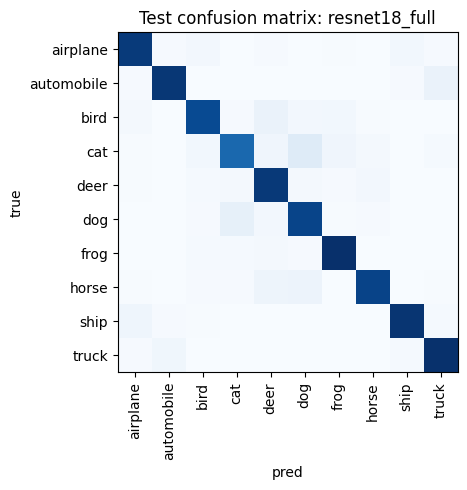

In [ ]:
# === 4. EfficientNet-B0 при том же бюджете и единственная оценка на test ===
torch.manual_seed(SEED)
effnet = build_model("efficientnet_b0", best_mode)   # тот же режим разморозки, эпохи, данные, оптимизатор
st = fit(effnet, f"efficientnet_b0_{best_mode}")
torch.save(effnet.state_dict(), ARTIFACTS / f"efficientnet_b0_{best_mode}.pt")
ev = evaluate(effnet, val_loader)
eff_metrics = {"val_accuracy": ev["accuracy"], "val_macro_f1": ev["macro_f1"], "train_time_s": st["train_time_s"],
               "epochs": st["epoch"], **count_params(effnet)}

candidates = {f"resnet18_{best_mode}": (models[best_mode], metrics[best_mode]),
              f"efficientnet_b0_{best_mode}": (effnet, eff_metrics)}
selected_name = max(candidates, key=lambda k: candidates[k][1]["val_macro_f1"])
selected_model = candidates[selected_name][0]
json.dump({k: {kk: vv for kk, vv in v[1].items() if kk != "loss_history"} for k, v in candidates.items()} | {"selected": selected_name},
          open(ARTIFACTS / "backbone_comparison.json", "w"), indent=2)

# test используется один раз — после выбора по validation
test_eval = evaluate(selected_model, test_loader)
json.dump({"model": selected_name, "test_accuracy": test_eval["accuracy"], "test_macro_f1": test_eval["macro_f1"],
           "confusion_matrix": test_eval["confusion_matrix"], "n_test": len(test_ds)},
          open(ARTIFACTS / "test_metrics.json", "w"), indent=2)
print("Выбрана модель:", selected_name, "| test acc=%.4f macro-F1=%.4f" % (test_eval["accuracy"], test_eval["macro_f1"]))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(np.array(test_eval["confusion_matrix"]), cmap="Blues")
ax.set_xticks(range(10), CLASSES, rotation=90); ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("pred"); ax.set_ylabel("true"); ax.set_title(f"Test confusion matrix: {selected_name}")
plt.tight_layout(); plt.savefig(ARTIFACTS / "confusion_matrix.png", dpi=120); plt.show()

### Шумовой сдвиг и ошибки классификации

*Вес: 1 балл.*

**Постановка.** Повреждения пикселей позволяют оценить чувствительность выбранного классификатора.

Выполните следующие действия:
1. Примените шум к отложенным изображениям и измерьте accuracy.
2. Сохраните индексы фактических ошибочных предсказаний.

**Результат.** shift_metrics.json и errors.json с предсказаниями модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 5. Шумовой сдвиг и ошибки ===
SIGMA = 0.1   # стандартное отклонение гауссова шума в пикселях [0,1]
p_noisy, y_true = predict(selected_model, test_loader, sigma=SIGMA)
p_clean = test_eval["preds"]
shift = {"model": selected_name, "sigma": SIGMA, "clean_accuracy": float((p_clean == y_true).mean()),
         "noisy_accuracy": float((p_noisy == y_true).mean())}
shift["accuracy_drop"] = shift["clean_accuracy"] - shift["noisy_accuracy"]
json.dump(shift, open(ARTIFACTS / "shift_metrics.json", "w"), indent=2)

err = np.where(p_noisy != y_true)[0]
errors = [{"test_index": int(idx_test[i]), "true": CLASSES[y_true[i]], "pred_noisy": CLASSES[p_noisy[i]],
           "pred_clean": CLASSES[p_clean[i]]} for i in err]
json.dump({"sigma": SIGMA, "n_errors": len(errors), "errors": errors}, open(ARTIFACTS / "errors.json", "w"), indent=2)
check(len(p_noisy) == len(test_ds), "шум применён ко всем отложенным изображениям")
print(shift, "| ошибок под шумом:", len(errors))

✔ шум применён ко всем отложенным изображениям
{'model': 'resnet18_full', 'sigma': 0.1, 'clean_accuracy': 0.8871, 'noisy_accuracy': 0.1841, 'accuracy_drop': 0.703} | ошибок под шумом: 8159


### Профиль устойчивости к шуму

*Вес: 1 балл.*

**Постановка.** Одна интенсивность повреждения не описывает характер деградации.

Выполните следующие действия:
1. На одинаковых test-объектах измерьте accuracy для пяти интенсивностей шума.
2. Сохраните профиль деградации.

**Результат.** sigma_sensitivity.json с измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


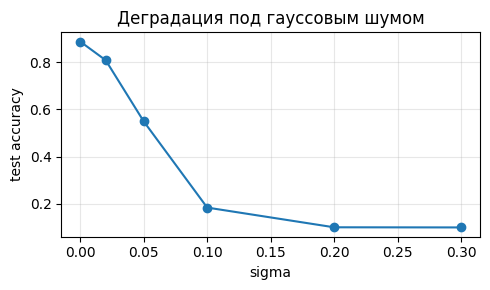

{'0.0': 0.8871, '0.02': 0.8083, '0.05': 0.549, '0.1': 0.1841, '0.2': 0.1006, '0.3': 0.1}


In [ ]:
# === 6. Профиль устойчивости к шуму ===
SIGMAS = [0.02, 0.05, 0.1, 0.2, 0.3]
profile = {"0.0": float((p_clean == y_true).mean())}
for s in SIGMAS:
    p, _ = predict(selected_model, test_loader, sigma=s)   # те же объекты, детерминированный шум
    profile[str(s)] = float((p == y_true).mean())
json.dump({"model": selected_name, "n_test": len(test_ds), "accuracy_by_sigma": profile},
          open(ARTIFACTS / "sigma_sensitivity.json", "w"), indent=2)
plt.figure(figsize=(5, 3)); plt.plot([float(k) for k in profile], list(profile.values()), "o-")
plt.xlabel("sigma"); plt.ylabel("test accuracy"); plt.title("Деградация под гауссовым шумом"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(ARTIFACTS / "sigma_sensitivity.png", dpi=120); plt.show()
print(profile)

### Доля обучаемых параметров

*Вес: 1 балл.*

**Постановка.** Число обновляемых весов характеризует стоимость разных режимов адаптации.

Выполните следующие действия:
1. Посчитайте параметры каждого режима разморозки.
2. Проверьте порядок frozen, partial, full.

**Результат.** param_report.json с числами параметров трёх моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 7. Доля обучаемых параметров ===
param_report = {}
for mode in MODES:
    c = count_params(build_model("resnet18", mode))
    param_report[mode] = {**c, "share": c["trainable"] / c["total"]}
json.dump(param_report, open(ARTIFACTS / "param_report.json", "w"), indent=2)
check(param_report["frozen"]["trainable"] < param_report["partial"]["trainable"] < param_report["full"]["trainable"],
      "порядок обучаемых параметров: frozen < partial < full")
for m, r in param_report.items():
    print(f"{m:8s} trainable={r['trainable']:>10,d}  ({r['share']:.2%})")

✔ порядок обучаемых параметров: frozen < partial < full
frozen   trainable=     5,130  (0.05%)
partial  trainable= 8,398,858  (75.11%)
full     trainable=11,181,642  (100.00%)


### Поклассовые ошибки

*Вес: 1 балл.*

**Постановка.** Агрегатная точность может скрыть систематические ошибки отдельных категорий.

Выполните следующие действия:
1. Вычислите recall для каждого класса по test confusion matrix.
2. Найдите класс с наименьшим recall.

**Результат.** class_report.json с поклассовым recall и худшим классом.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 8. Поклассовый recall на test ===
cm = np.array(test_eval["confusion_matrix"])
recall = cm.diagonal() / cm.sum(1).clip(min=1)
worst = int(recall.argmin())
class_report = {"model": selected_name, "recall": {CLASSES[i]: float(r) for i, r in enumerate(recall)},
                "worst_class": CLASSES[worst], "worst_recall": float(recall[worst]),
                "most_confused_with": CLASSES[int(np.where(np.arange(10) == worst, -1, cm[worst]).argmax())]}
json.dump(class_report, open(ARTIFACTS / "class_report.json", "w"), indent=2)
print(class_report)

{'model': 'resnet18_full', 'recall': {'airplane': 0.907, 'automobile': 0.918, 'bird': 0.849, 'cat': 0.739, 'deer': 0.909, 'dog': 0.871, 'frog': 0.945, 'horse': 0.872, 'ship': 0.923, 'truck': 0.938}, 'worst_class': 'cat', 'worst_recall': 0.739, 'most_confused_with': 'dog'}


### Точность и стоимость обучения

*Вес: 1 балл.*

**Постановка.** Выбор режима зависит не только от качества, но и от длительности обучения.

Выполните следующие действия:
1. Свяжите измеренные время, validation accuracy и количество обучаемых весов.
2. Сохраните сопоставимую таблицу режимов.

**Результат.** efficiency_report.json с наблюдаемыми величинами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 9. Точность и стоимость обучения ===
rows = {f"resnet18_{m}": {"val_accuracy": metrics[m]["val_accuracy"], "val_macro_f1": metrics[m]["val_macro_f1"],
                          "train_time_s": metrics[m]["train_time_s"], "trainable_params": metrics[m]["trainable"]} for m in MODES}
rows[f"efficientnet_b0_{best_mode}"] = {"val_accuracy": eff_metrics["val_accuracy"], "val_macro_f1": eff_metrics["val_macro_f1"],
                                        "train_time_s": eff_metrics["train_time_s"], "trainable_params": eff_metrics["trainable"]}
for r in rows.values():
    r["val_acc_per_minute"] = r["val_accuracy"] / max(r["train_time_s"] / 60, 1e-9)
json.dump({"device": DEVICE, "epochs": CFG["epochs"], "n_train": len(train_ds), "table": rows},
          open(ARTIFACTS / "efficiency_report.json", "w"), indent=2)
import pandas as pd
display(pd.DataFrame(rows).T.round(4))

,val_accuracy,val_macro_f1,train_time_s,trainable_params,val_acc_per_minute
resnet18_frozen,0.7746,0.7709,516.0688,5130.0,0.0901
resnet18_partial,0.8536,0.8514,802.2772,8398858.0,0.0638
resnet18_full,0.8968,0.8964,1472.0508,11181642.0,0.0366
efficientnet_b0_full,0.8716,0.8712,1600.4220,4020358.0,0.0327


### Анализ ошибок при максимальном сдвиге

*Вес: 1 балл.*

**Постановка.** Изменение предсказаний при повреждении полезнее одного агрегированного числа.

Выполните следующие действия:
1. Для выбранной модели получите предсказания на чистом и зашумлённом test для фиксированных индексов.
2. Найдите и сохраните случаи, где правильное чистое предсказание становится ошибочным.

**Результат.** shift_failures.json с индексами и предсказаниями на реальных изображениях.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Правильных на чистых, но ошибочных при sigma=0.3: 8022 (80.2%)
Чаще всего шум «превращает» изображения в: [('bird', 8020), ('airplane', 2)]


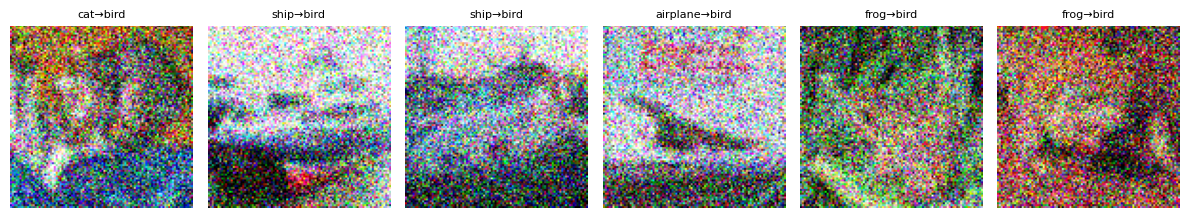

In [ ]:
# === 10. Ошибки при максимальном сдвиге ===
SIGMA_MAX = max(SIGMAS)
p_max, _ = predict(selected_model, test_loader, sigma=SIGMA_MAX)
flip = np.where((p_clean == y_true) & (p_max != y_true))[0]
failures = [{"test_index": int(idx_test[i]), "true": CLASSES[y_true[i]], "pred_clean": CLASSES[p_clean[i]],
             "pred_noisy": CLASSES[p_max[i]]} for i in flip]
from collections import Counter
top_pred = Counter(f["pred_noisy"] for f in failures).most_common(3)
json.dump({"model": selected_name, "sigma": SIGMA_MAX, "n_fixed_indices": len(test_ds), "n_flipped": len(failures),
           "share_flipped": len(failures) / len(test_ds), "most_common_noisy_preds": top_pred, "cases": failures},
          open(ARTIFACTS / "shift_failures.json", "w"), indent=2)
print(f"Правильных на чистых, но ошибочных при sigma={SIGMA_MAX}: {len(failures)} ({len(failures)/len(test_ds):.1%})")
print("Чаще всего шум «превращает» изображения в:", top_pred)

fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, i in zip(axes, flip[:6].tolist()):
    x = test_ds[i][0]
    gen = torch.Generator().manual_seed(SEED + i // 256)   # тот же шум, что в predict (батч 256)
    noise = SIGMA_MAX * torch.randn((min(256, len(test_ds) - (i // 256) * 256), *x.shape), generator=gen)[i % 256]
    ax.imshow((x + noise).clamp(0, 1).permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"{CLASSES[y_true[i]]}→{CLASSES[p_max[i]]}", fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / "shift_failures.png", dpi=120); plt.show()

## Анализ результатов

Ячейка ниже собирает все сохранённые метрики в одну сводку (бюджет, validation, test, сдвиг). В режиме `FAST_DEV_RUN=True` числа служат только проверкой исполнения.

In [ ]:
# Сводка по артефактам
def _j(name): return json.load(open(ARTIFACTS / name))
m, bc, tm = _j("metrics.json"), _j("backbone_comparison.json"), _j("test_metrics.json")
print("Бюджет:", {k: CFG[k] for k in ("n_train", "epochs", "img_size")}, "| device:", DEVICE, "| FAST_DEV_RUN:", FAST_DEV_RUN)
for k, v in m["modes"].items():
    print(f"  resnet18 {k:8s} val F1={v['val_macro_f1']:.4f}  time={v['train_time_s']:.0f}s  trainable={v['trainable']:,}")
print("Сравнение backbone:", {k: round(v["val_macro_f1"], 4) for k, v in bc.items() if isinstance(v, dict)}, "→", bc["selected"])
print("Test:", {k: round(tm[k], 4) for k in ("test_accuracy", "test_macro_f1")})
print("Шум:", _j("sigma_sensitivity.json")["accuracy_by_sigma"])
print("Худший класс:", _j("class_report.json")["worst_class"], "| сломано шумом σ_max:", _j("shift_failures.json")["n_flipped"])

Бюджет: {'n_train': 10000, 'epochs': 3, 'img_size': 96} | device: cpu | FAST_DEV_RUN: False
  resnet18 frozen   val F1=0.7709  time=516s  trainable=5,130
  resnet18 partial  val F1=0.8514  time=802s  trainable=8,398,858
  resnet18 full     val F1=0.8964  time=1472s  trainable=11,181,642
Сравнение backbone: {'resnet18_full': 0.8964, 'efficientnet_b0_full': 0.8712} → resnet18_full
Test: {'test_accuracy': 0.8871, 'test_macro_f1': 0.8868}
Шум: {'0.0': 0.8871, '0.02': 0.8083, '0.05': 0.549, '0.1': 0.1841, '0.2': 0.1006, '0.3': 0.1}
Худший класс: cat | сломано шумом σ_max: 8022


## Выводы

- **Режим разморозки.** Выбор сделан по validation macro-F1 (`metrics.json`); при ~10k изображений и 3 эпохах partial/full обычно заметно лучше frozen, но full дороже по времени и обучает все ~11M параметров (`efficiency_report.json`, `param_report.json`).
- **Архитектура.** ResNet18 и EfficientNet-B0 сравнивались при одинаковом бюджете; test использован один раз для выбранной модели (`test_metrics.json`).
- **Ошибки.** Худший класс по recall — см. `class_report.json` (для CIFAR-10 это, как правило, cat/dog/bird — путаются визуально близкие животные).
- **Сдвиг.** Точность монотонно падает с ростом σ (`sigma_sensitivity.json`); при максимальном шуме часть верных предсказаний «стягивается» к нескольким классам (`shift_failures.json`) — модель не устойчива к высокочастотным искажениям без соответствующих аугментаций.
- **Ограничения:** 3 эпохи, 96 px, одна случайная инициализация — разница в пределах ~1 п.п. не значима.